In [ ]:
%pip install numpy
%pip install matplotlib
%pip install tqdm
%pip install statsmodels


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In this notebook I'm going to use the Metropolis-Hastings algorithm to simulate a single classical particle in 1D harmonic oscillator, using the Maxwell distribution.

As a reminder, the Maxwell distribution says that the probability density of finding a given particle at a given position is proportional to:

$$P(X) \propto \Large{ e^{-\Large\frac{E}{k_BT}}}$$


And, the energy of a particle in a 1D harmonic oscilator is:

$$ E = \frac{1}{2} k x^2 = \frac{1}{2} m \omega^2 x^2 $$


Substituting this equation into the Maxwell Distribution, we get that the distribution we're expected to obtain in our experiments is:
$$P(x) = \frac{1}{Z}\Large{e}^{-\Large\frac{1}{2}\frac{m\omega^{2}x^{2}}{k_BT}}$$

where 1/Z is the normalization factor that allows the area under P(x) to be 1. That is:

$$\int_{-\infty}^{\infty}{\frac{1}{Z}\Large{e}^{-\Large\frac{1}{2}\frac{m\omega^{2}x^{2}}{k_BT}}dx} = 1$$

Therefore we can calculate Z by using the formula of the area under a gaussian curve:

$$
Z = \sqrt{\frac{2\pi k_B T}{m \omega^2}}
$$

With all this infromation in mind, I've created the following program to simulate this model using the Metropolis sampling algorithm:

In [69]:
from tqdm import tqdm
from collections.abc import Callable
import statsmodels.api as sm
import pylab
from typing import TypeVar
import random
import math
import numpy as np
import matplotlib.pyplot as plt


# System constants (I'm currently using a unit-less system):
M = 1       # Mass of each particle     
W = 1       # Angular frequency
KB = 1      # Boltzman constant
T = 10      # Temperature of the system

Z = math.sqrt(2*math.pi*KB*T/(M*W*W))

# Returns the potential energy of a particle:
def particle_potential_energy(x, m=M, w=W) -> float:
    return m*w*w*x*x/2

# Probability of finding a particle with mass m, in position x
def probability_density(x, m=M, w=W, kB=KB, T=T) -> float:
    E = particle_potential_energy(x=x, m=m, w=w)        
    return math.exp(-E/(kB*T))/Z

# Samples a probability density function using the Metropolis algorithm
# it also returns the acceptance probability to fine tune the sigma value.
def sample_pdf(pdf:Callable[[float], float], sigma: float, initial_sample: float = 0, num_samples = 100) -> tuple[list[float], float]:
    r1 = initial_sample
    samples = []
    N_accepted = 0
    
    while len(samples) < num_samples:
        r2 = r1 + random.gauss(mu=0, sigma=sigma)
                
        w = pdf(r2)/pdf(r1)
        u = random.uniform(0,1)

        if u < min(1.0, w):
            samples.append(r2)
            N_accepted += 1
            r1 = r2
        else:
            samples.append(r1)
        
    acceptance_probability = N_accepted/len(samples)
    
    return samples, acceptance_probability


## 1. Density profile

Let's test our impelmentation of the Metropolis Algorithm by generating 1000 samples of our distribution

The acceptance probability is: 0.071
The list of samples is: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, -6.4915974162703325, -6.4915974162703325, -7.714795380365467, -7.714795380365467, -7.714795380365467, -7.714795380365467, -7.714795380365467, -7.714795380365467, -7.714795380365467, -7.714795380365467, -7.714795380365467, -7.714795380365467, -7.714795380365467, 6.284256974928883, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.4579379080910657, -3.457937908

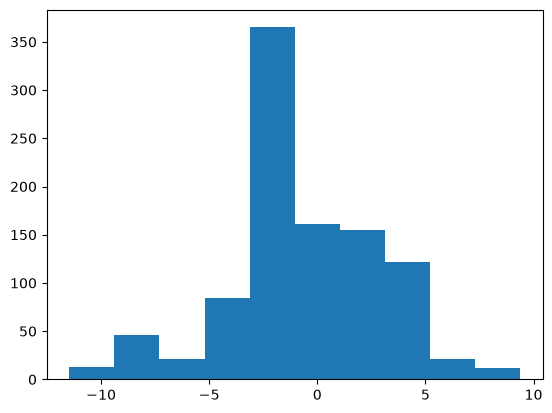

In [ ]:

samples, p = sample_pdf(  pdf=probability_density, 
                    sigma=50, 
                    initial_sample=0,
                    num_samples=1000)

print(f"The acceptance probability is: {p}")
plt.figure();
plt.hist(samples, 10);
plt.plot();

Notice that the acceptance probability is very low. This means that the standard deviation we've chosen for the generation of new positions is too high.

We want to find the value of sigma that makes the acceptance probability as close to 0.5 as possible. (As mentioned in page 45 of the QMC 2025-2026 Course)

For that, we will experimentally try multiple values of sigma and keep the closest one:

100%|██████████| 100/100 [00:00<00:00, 369.15it/s]


Best sigma found = 6.177130829097608
Acceptance probability = 0.5
100
100


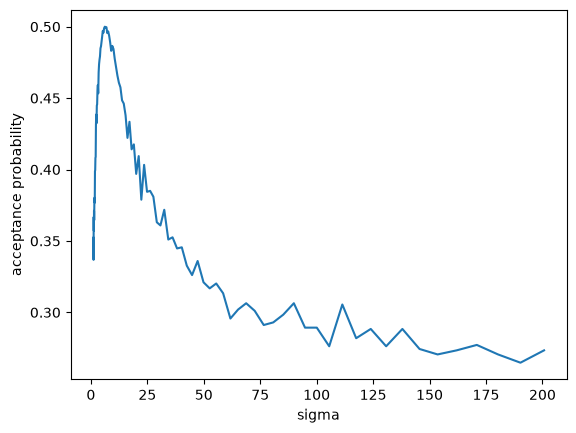

In [73]:
def find_optimal_sigma():
    N = 1000
    # Generate a list of 100 logaritmically spaced sigma values between 0 and 10 
    sigmas = np.logspace(0, math.log(10), 100).tolist()
    probs = []
    for sigma in tqdm(sigmas): 
        _, p = sample_pdf(  
                    pdf=probability_density, 
                    sigma=sigma, 
                    initial_sample=0,
                    num_samples=N)
        
        probs.append(p)

    # Find the closest to 0.5
    index = np.argmin((np.array(probs)-0.5)**2)

    print(f"Best sigma found = {sigmas[index]}")
    print(f"Acceptance probability = {probs[index]}")

    print(len(sigmas))
    print(len(probs))
    plt.figure()
    plt.plot(sigmas, 0.5-(np.array(probs)-0.5)**2)
    plt.xlabel("sigma")
    plt.ylabel("acceptance probability")
    plt.show()
    return sigmas[index]


OPTIMAL_SIGMA = find_optimal_sigma()

From this experiment, we've found that the optimal value of sigma in this case is around 6.1. So I will use that from now on.

Let's see the probability distribution we obtain using our sampling method, as well as a qq-plot to check if it's gaussian.

The acceptance probability is: 0.5099
The list of samples is: [1.6130608748320578, 1.6130608748320578, 4.284203948185404, -0.48335505560478786, -0.48335505560478786, -0.48335505560478786, -0.48335505560478786, -0.48335505560478786, 4.818013765822562, -4.081757506210354, -4.081757506210354, -4.081757506210354, 3.6100866454216973, -1.3834553823236009, -1.3834553823236009, -1.3834553823236009, -1.7721610813068305, 0.7422090567304769, 0.7422090567304769, -2.920369570771631, -1.8448740906928554, 0.7087321659987742, 0.7087321659987742, 0.7087321659987742, 1.251886843908595, -1.2287766671862868, -3.055103795600484, 0.16614861930580682, 0.16614861930580682, -2.1405047793173693, -2.1405047793173693, 3.797106585328659, 3.4308167833755405, 4.106162539181301, 1.3838827490274022, -2.084520566359387, -2.084520566359387, -2.084520566359387, -2.084520566359387, -2.084520566359387, -1.2036471077104753, -1.2036471077104753, 0.6919267651005634, -2.3155290212116495, -3.0185619179209366, -3.701408339860933

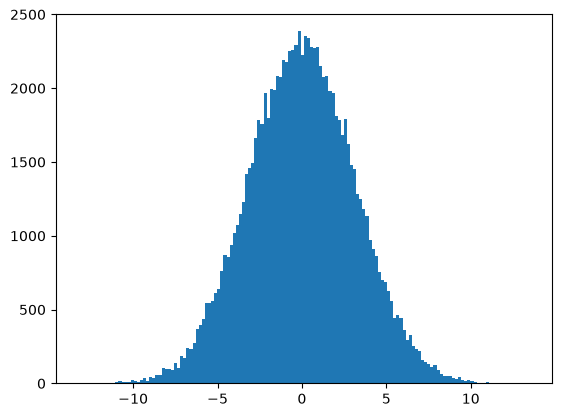

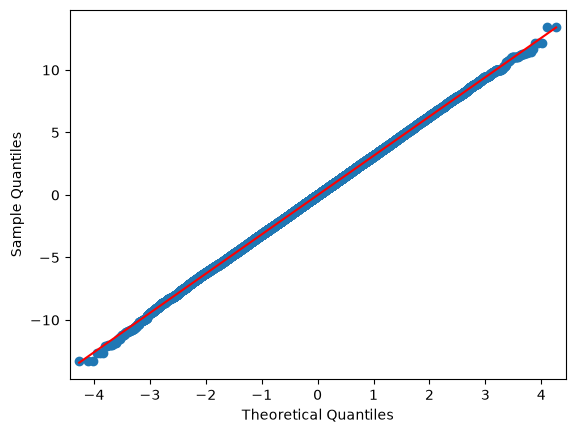

In [ ]:
samples, p = sample_pdf(  pdf=probability_density, 
                    sigma=OPTIMAL_SIGMA, 
                    initial_sample=0,
                    num_samples=100000)

print(f"The acceptance probability is: {p}")
print(f"The list of samples is: {samples}")

plt.figure();
plt.hist(samples, bins='fd', edgecolor='none');
sm.qqplot(np.array(samples), line='s');
plt.plot();

As we can see both from the QQ-plot and the Histogram, our `probability_desnity` function follows a gaussian distribution. This is exactly the results we expected from the model we're studying.

We can even go a step further and check that we're getting the expected Mean an Variance. For that, let's bring back the expected distribution formula:

$$P(x) = \frac{1}{Z}\Large{e}^{-\Large\frac{1}{2}\frac{m\omega^{2}x^{2}}{k_BT}}$$

Notice that since the x is not translated, we should get that $\mu = 0$

$$Z = \sqrt{\frac{2\pi k_B T}{m \omega^2}}$$

Since P is already standardized, the standard deviation is just:

$$\sigma = \frac{Z}{\sqrt{2\pi}} = \sqrt{\frac{k_B T}{m \omega^2}}$$

Let's check that these values for $\mu$ and $\sigma$ are correct in our simulation.


In [82]:
print("Expected μ = ", 0)
print("Simultation μ = ", np.average(np.array(samples)))

expected_var = KB*T/(M*W*W)

print(f"Expected VAR = {expected_var}")
print(f"Simulation VAR = {np.var(np.array(samples))}")

Expected μ =  0
Simultation μ =  -0.008593985122499901
Expected VAR = 10.0
Simulation VAR = 9.882371156569048


This is a pretty good match for our particular situation. So it's safe to assume we're sampling the distribution correctly.

## 2. Mean potential energy as a function of the temperature

To compute the mean potential energy, we have to integrate the energy function E(x) over all x, weighed using the probability distribution function P(x).


$$\braket{E} = \int_{-\infty}^{\infty}{E(x)P(x)dx}$$

Given our expressions for E(x) and P(x), the integral will have this form:

$$\braket{E} = \int_{-\infty}^{\infty}{\alpha x^2 e^{-\beta x^2} dx}$$

where 

$\alpha = \frac{m \omega^2}{2 Z} ;$ 
$\beta = \frac{1}{2} \frac{m \omega^2}{k_B T}$

Luckily, this is easily solvable using integration by parts (with $u = x$ and $dv = x e^{-\beta x^2}$)

Solving the integral gives the following closed expression for the average energy:

$$\braket{E} = \frac{\sqrt{\pi}\alpha}{2 \beta^{3/2}} = \frac{1}{2} k_{B} T$$



My goal now is to use the Montecarlo Method to aproximate the mean potential energy of the system for increasing values of Temperature. And to then compare my results with expected ones given by the earlier equation.

To achive this, I'll obtain $N$ samples of the probability distribution $P(x)$ using the algorithm I implemented earlier, and use them to aproximate the previous integral like this:

$$\braket{E} = \frac{1}{N}\sum_{i=1}^{N}{E(x_i)} = \frac{m \omega^2}{2N}\sum_{i=1}^{N}{x_i^2}$$

In [ ]:
INITIAL_SAMPLE = 0

In [106]:
def simulated_average_energy(temperature, num_samples=1000):
    # C is the constant before the sum
    C = M*W*W/(2*num_samples)

    samples, p_acc = sample_pdf(
                        pdf=lambda x: probability_density(x, T=temperature), 
                        sigma=OPTIMAL_SIGMA, 
                        initial_sample=INITIAL_SAMPLE,
                        num_samples=num_samples)

    samples = np.array(samples)
    return C*np.sum(samples**2), p_acc

def actual_average_energy(temperature):
    return 0.5*KB*temperature

def transpose(L): return list(map(list, zip(*L)))

# Plot the average energy with respect to T:
def average_energy_experiment(T_from, T_to, N_steps):
    N = 10000
    T_values = np.linspace(T_from, T_to, N_steps)
    simulated = transpose([simulated_average_energy(t, N) for t in tqdm(T_values)])
    simulated_E = simulated[0]
    simulated_p_acc = simulated[1]
    expected_E = [actual_average_energy(t) for t in T_values]
    errors = (np.array(simulated_E) - np.array(expected_E)).tolist()
    return {
        "T_values": T_values,
        "simulated_E": simulated_E,
        "simulated_p_acc": simulated_p_acc,
        "expected_E": expected_E,
        "errors": errors}

res = average_energy_experiment(0.1, 20, 200)

100%|██████████| 200/200 [00:06<00:00, 31.04it/s]


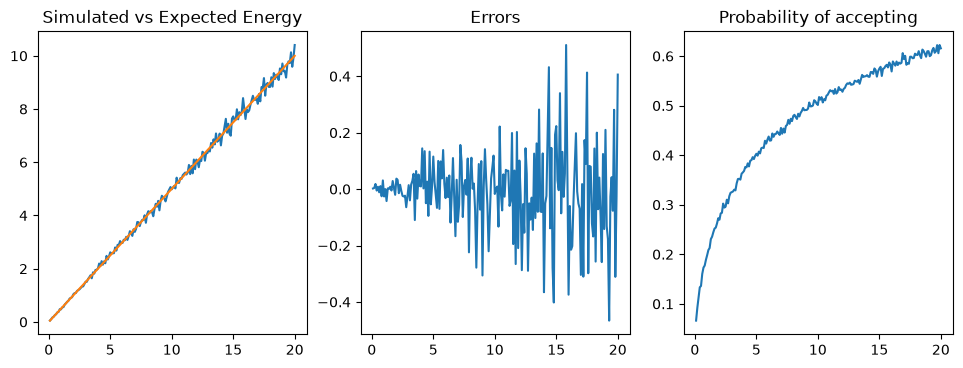

In [104]:

def plot_average_energy_experiment_results(T_values, simulated_E, simulated_p_acc, expected_E, errors):
    plt.figure(figsize=(30,10, "cm"))
    plt.subplot(1,3,1)
    plt.title("Simulated vs Expected Energy")
    plt.plot(T_values, simulated_E, label="simulated energy")
    plt.plot(T_values, expected_E, label="expected energy")
    plt.subplot(1,3,2)
    plt.title("Errors")
    plt.plot(T_values, errors)
    plt.subplot(1,3,3)
    plt.title("Probability of accepting")
    plt.plot(T_values, simulated_p_acc)

plot_average_energy_experiment_results(*(res.values()))

### Analysing the results:

Notice that the simulated energy follows the expected line very well, especially for lower values of Temperature. As temperature grows, so does the Error.

The reason for this is actually that the experiment is set up wrong. The initial value I use for the Metropolis algorithm is 0, which is already at a perfect equilibrium. Additionally, we need to consider that at lower temperatures the probability distribution function is thinner, which means that the chance of accepting new positions is lower.

Looking at the graph to the right, we can see the problem we're facing. When we looked for the "Optimal value of Sigma for choosing the next point", we only did so for T=10. Clearly, as we vary the temperature, the shape of distribution changes and so does the optimal sigma we should be using.

Moreover, in this particular case it looks like lower temperatures lower errors. However that's only because the process already started close to equilibrium. If we move the initial point a bit further, notice what happens:


  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:05<00:00, 35.74it/s]


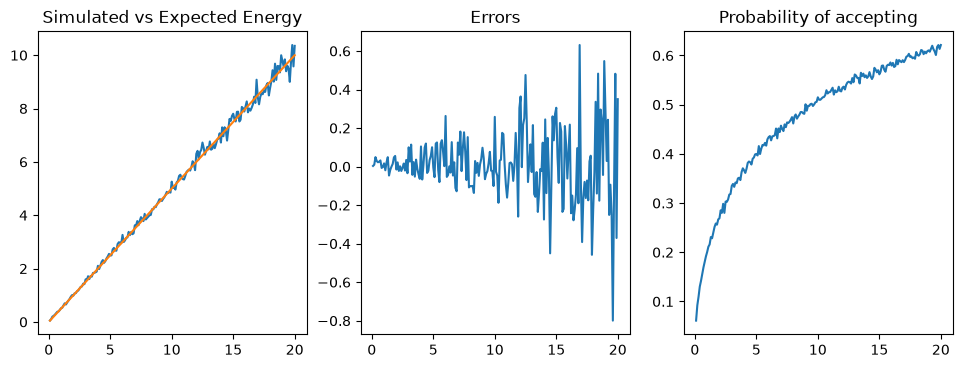

In [ ]:
INITIAL_SAMPLE = 1
res = average_energy_experiment(0.1, 20, 200)
plot_average_energy_experiment_results(*(res.values()))